<a href="https://colab.research.google.com/github/Manawariqbal/Deep-Learning/blob/main/Handwritten_Digit_Recognition.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense,Flatten
from tensorflow.keras.utils import to_categorical


In [ ]:
#load the dataset

(X_train,y_train),(X_test,y_test) = mnist.load_data()
print("Training images",X_train.shape)
print("Training labels",y_train.shape)
print("Testing images",X_test.shape)

print("Testing labels",y_test.shape)


Training images (60000, 28, 28)
Training labels (60000,)
Testing images (10000, 28, 28)
Testing labels (10000,)


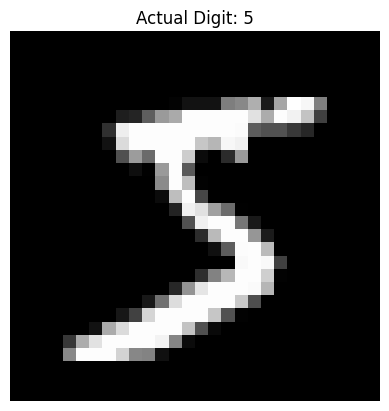

In [ ]:
#Display a sample image
plt.imshow(X_train[0],cmap="gray")
plt.title(f"Actual Digit: {y_train[0]}")
plt.axis("off")
plt.show()

In [ ]:
#Normalize pixels from 0 to 255 to 0 to1
X_train=X_train.astype("float32")/255
X_test=X_test.astype("float32")/255

In [ ]:
#One hot coding for y
y_train_encoded=to_categorical(y_train,10)
y_test_encoded=to_categorical(y_test,10)


In [ ]:
#Build the ANN Model
model=Sequential(
    [
        Flatten(input_shape=(28,28)),
        Dense(128,activation="relu"),
        Dense(64,activation="relu"),
        Dense(10,activation="softmax")




     ]
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
#Compile the model

model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Train the model
history=model.fit(X_train,y_train_encoded,epochs=10,batch_size=32,validation_split=0.1)


Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9233 - loss: 0.2602 - val_accuracy: 0.9662 - val_loss: 0.1125
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9674 - loss: 0.1073 - val_accuracy: 0.9710 - val_loss: 0.0907
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9768 - loss: 0.0752 - val_accuracy: 0.9750 - val_loss: 0.0872
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9823 - loss: 0.0570 - val_accuracy: 0.9750 - val_loss: 0.0925
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9867 - loss: 0.0427 - val_accuracy: 0.9800 - val_loss: 0.0784
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9881 - loss: 0.0354 - val_accuracy: 0.9792 - val_loss: 0.0817
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9913 - loss: 0.0269 - val_accuracy: 0.9763 - val_loss: 0.0973
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.9917 - loss: 0.0251 - 

In [ ]:
#Evaluate the model
test_loss,test_acc=model.evaluate(X_test,y_test_encoded)
print("Test Loss:",test_loss)
print("Test Accuracy:",test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.9761 - loss: 0.0914
Test Loss: 0.09141973406076431
Test Accuracy: 0.9761000275611877


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


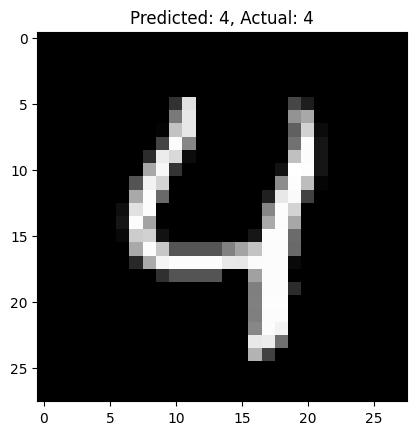

In [ ]:
#Predict a digit
prediction=model.predict(X_test[:5],verbose=True)
for i in range(5):
  predicted_digit=np.argmax(prediction[i])
  actual_digit=y_test[i]
  plt.imshow(X_test[i],cmap="gray")
  plt.title(f"Predicted: {predicted_digit}, Actual: {actual_digit}")
  plt.axis

In [ ]:
#save the model
model.save("handwritten_digit_ann.keras")
